<a href="https://colab.research.google.com/github/tristansalazar/MachineLearning-/blob/main/Unidad2/Asesinatos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from IPython.display import Markdown, display

display(Markdown("""
# Machine Learning y Deep Learning

**Unidad 2**

**Proyecto:** Análisis Predictivo de la Tasa de Asesinatos

**Facilitador:** *Dr. José Gabriel Rodríguez Rivas*

**Alumno:** Diego Tristán Salazar Rueda

## Objetivo General

Explorar y comparar la capacidad predictiva y la interpretabilidad de diversos algoritmos de regresión. Utilizando un dataset de 3,000 registros, se predice la variable objetivo **tasa_asesinatos_por_100mil** a partir de variables socioeconómicas y demográficas.

**Variable Objetivo (Y):** tasa_asesinatos_por_100mil

**Variables Predictoras (X):**
- indice_gini
- tasa_desempleo_juvenil
- porcentaje_sin_diploma_secundaria
- ingresos_medios
- densidad_poblacional
- gasto_policial_per_capita
- inversion_programas_sociales_per_capita

**Métrica de Evaluación:** Coeficiente de Determinación (R²)

**Algoritmos:** Regresión Lineal Múltiple, Árbol de Decisión, Random Forest, SVR y XGBoost.
"""))


# Machine Learning y Deep Learning

**Unidad 2**

**Proyecto:** Análisis Predictivo de la Tasa de Asesinatos

**Facilitador:** *Dr. José Gabriel Rodríguez Rivas*

**Alumno:** Diego Tristán Salazar Rueda

## Objetivo General

Explorar y comparar la capacidad predictiva y la interpretabilidad de diversos algoritmos de regresión. Utilizando un dataset de 3,000 registros, se predice la variable objetivo **tasa_asesinatos_por_100mil** a partir de variables socioeconómicas y demográficas.

**Variable Objetivo (Y):** tasa_asesinatos_por_100mil

**Variables Predictoras (X):**
- indice_gini
- tasa_desempleo_juvenil
- porcentaje_sin_diploma_secundaria
- ingresos_medios
- densidad_poblacional
- gasto_policial_per_capita
- inversion_programas_sociales_per_capita

**Métrica de Evaluación:** Coeficiente de Determinación (R²)

**Algoritmos:** Regresión Lineal Múltiple, Árbol de Decisión, Random Forest, SVR y XGBoost.


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from xgboost import XGBRegressor

df = pd.read_csv("Asesinatos.csv", encoding="latin-1")
df.head()

,Estado,id_area,habitantes,area_km2,ingresos_medios,edad_media_poblacion,densidad_poblacional,indice_gini,tasa_desempleo_juvenil,porcentaje_sin_diploma_secundaria,porcentaje_hogares_monoparentales,gasto_policial_per_capita,inversion_programas_sociales_per_capita,tiempo_respuesta_emergencias_min,porcentaje_zonas_verdes,tasa_asesinatos_por_100mil
0,Puebla,1,207953,26.70,48018,40.8,7787.47,0.522,21.8,30.3,40.0,867,240,3.0,5.0,27.1
1,Durango,2,80226,17.39,50295,42.4,4612.66,0.346,19.2,18.9,23.5,706,458,3.0,11.1,13.6
2,Tabasco,3,260806,70.69,50795,39.5,3689.22,0.417,23.0,33.5,23.8,981,403,4.3,8.1,20.6
3,Baja California Sur,4,969508,830.49,68910,27.3,1167.39,0.399,28.8,17.7,23.5,951,326,7.5,16.1,18.5
4,Aguascalientes,5,69478,30.59,54248,36.2,2271.26,0.422,16.4,33.6,27.6,563,353,7.2,10.6,16.8


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 16 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Estado                                   3000 non-null   object 
 1   id_area                                  3000 non-null   int64  
 2   habitantes                               3000 non-null   int64  
 3   area_km2                                 3000 non-null   float64
 4   ingresos_medios                          3000 non-null   int64  
 5   edad_media_poblacion                     3000 non-null   float64
 6   densidad_poblacional                     3000 non-null   float64
 7   indice_gini                              3000 non-null   float64
 8   tasa_desempleo_juvenil                   3000 non-null   float64
 9   porcentaje_sin_diploma_secundaria        3000 non-null   float64
 10  porcentaje_hogares_monoparentales        3000 no

In [9]:
X = df[['indice_gini', 'tasa_desempleo_juvenil', 'porcentaje_sin_diploma_secundaria',
        'ingresos_medios', 'densidad_poblacional', 'gasto_policial_per_capita',
        'inversion_programas_sociales_per_capita']]
y = df['tasa_asesinatos_por_100mil']

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
rlm = LinearRegression()
rlm.fit(X_train, y_train)

y_pred = rlm.predict(X_test)
r2_rlm1 = r2_score(y_test, y_pred)

print(f"Error cuadrático medio (MSE): {mean_squared_error(y_test, y_pred):.2f}")
print(f"Coeficiente de determinación (R²): {r2_rlm1:.4f}")

Error cuadrático medio (MSE): 9.01
Coeficiente de determinación (R²): 0.5533


In [12]:
coef_df = pd.DataFrame({
    'Variable': X.columns,
    'Coeficiente': rlm.coef_
}).sort_values('Coeficiente', ascending=False)

print(coef_df)
print(f"Intersección (bias): {rlm.intercept_:.2f}")

                                  Variable  Coeficiente
0                              indice_gini    40.329482
1                   tasa_desempleo_juvenil     0.325243
2        porcentaje_sin_diploma_secundaria     0.127969
4                     densidad_poblacional    -0.000005
3                          ingresos_medios    -0.000076
6  inversion_programas_sociales_per_capita    -0.000949
5                gasto_policial_per_capita    -0.001828
Intersección (bias): -2.99


In [13]:
scaler_rlm = StandardScaler()
X_train_std = scaler_rlm.fit_transform(X_train)

rlm_std = LinearRegression()
rlm_std.fit(X_train_std, y_train)

coef_std = pd.DataFrame({
    'Variable': X.columns,
    'Coef. estandarizado': rlm_std.coef_
}).sort_values('Coef. estandarizado', key=abs, ascending=False)

print(coef_std)

                                  Variable  Coef. estandarizado
0                              indice_gini             2.110357
1                   tasa_desempleo_juvenil             1.604630
2        porcentaje_sin_diploma_secundaria             1.274626
3                          ingresos_medios            -0.997597
5                gasto_policial_per_capita            -0.317031
6  inversion_programas_sociales_per_capita            -0.095234
4                     densidad_poblacional            -0.007721


In [14]:
vars_sub = ['indice_gini', 'tasa_desempleo_juvenil', 'ingresos_medios', 'porcentaje_sin_diploma_secundaria']

rlm2 = LinearRegression()
rlm2.fit(X_train[vars_sub], y_train)

y_pred = rlm2.predict(X_test[vars_sub])
r2_rlm2 = r2_score(y_test, y_pred)

print(f"R² con variables iniciales: {r2_rlm1:.4f}")
print(f"R² con subconjunto: {r2_rlm2:.4f}")

R² con variables iniciales: 0.5533
R² con subconjunto: 0.5505


In [15]:
tree1 = DecisionTreeRegressor(max_depth=4, random_state=42)
tree1.fit(X_train, y_train)

r2_tree1_train = r2_score(y_train, tree1.predict(X_train))
r2_tree1 = r2_score(y_test, tree1.predict(X_test))

print(f"R² entrenamiento: {r2_tree1_train:.4f}")
print(f"R² prueba: {r2_tree1:.4f}")

R² entrenamiento: 0.4345
R² prueba: 0.3656


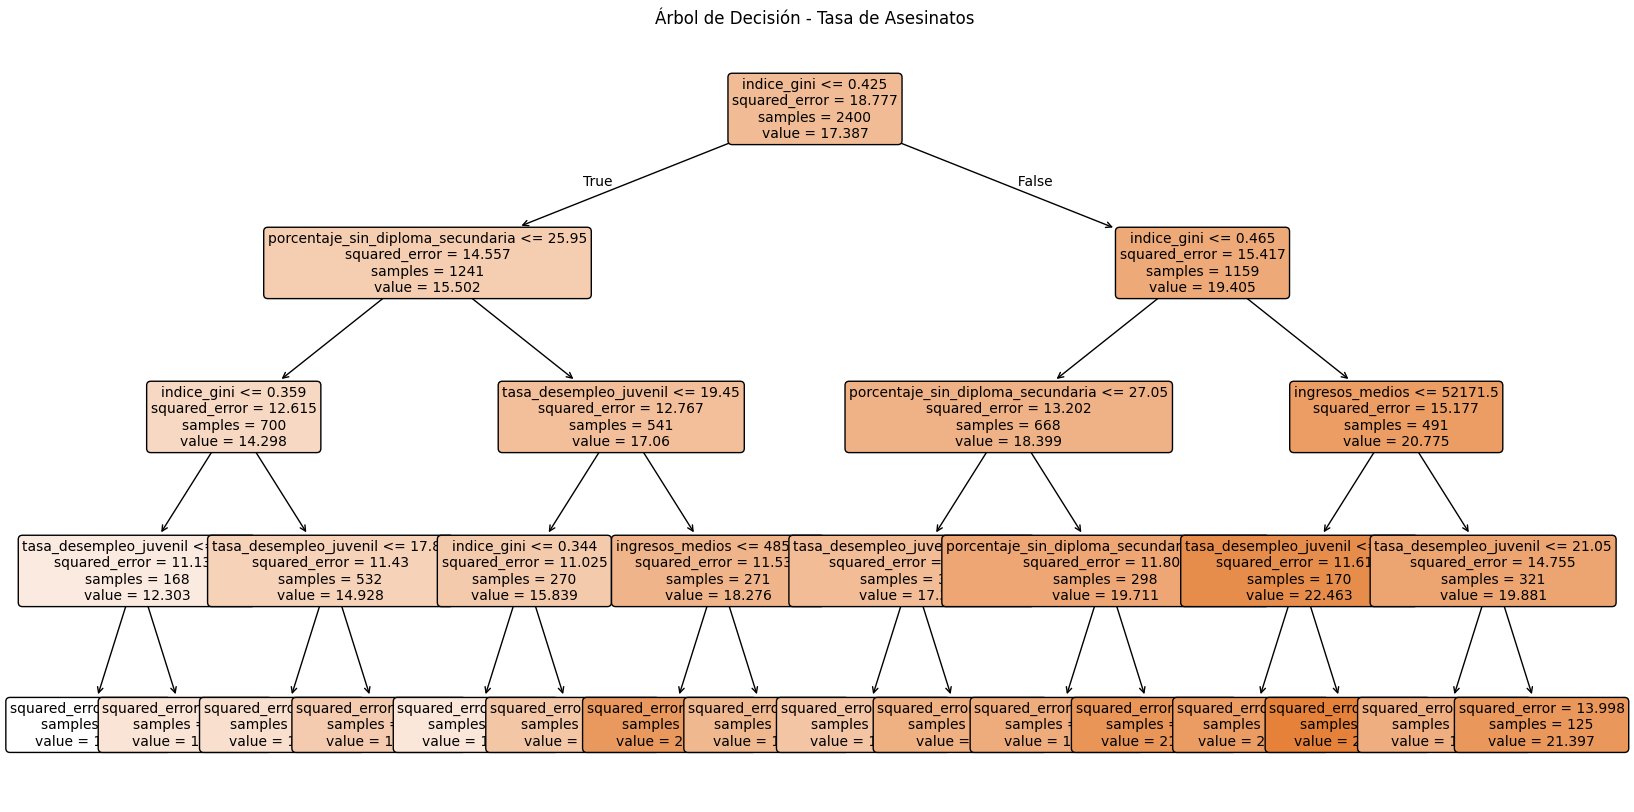

In [16]:
plt.figure(figsize=(20, 10))
plot_tree(tree1,
          feature_names=list(X.columns),
          filled=True,
          rounded=True,
          fontsize=10)
plt.title("Árbol de Decisión - Tasa de Asesinatos")
plt.show()

In [17]:
tree2 = DecisionTreeRegressor(random_state=42)
tree2.fit(X_train, y_train)

r2_tree2_train = r2_score(y_train, tree2.predict(X_train))
r2_tree2 = r2_score(y_test, tree2.predict(X_test))

print(f"R² entrenamiento: {r2_tree2_train:.4f}")
print(f"R² prueba: {r2_tree2:.4f}")

R² entrenamiento: 1.0000
R² prueba: 0.0427


In [18]:
imp_tree = pd.DataFrame({
    'Variable': X.columns,
    'Importancia max_depth=4': tree1.feature_importances_,
    'Importancia sin límite': tree2.feature_importances_
}).sort_values('Importancia max_depth=4', ascending=False)

print(imp_tree)

                                  Variable  Importancia max_depth=4  \
0                              indice_gini                 0.609348   
2        porcentaje_sin_diploma_secundaria                 0.182583   
1                   tasa_desempleo_juvenil                 0.151059   
3                          ingresos_medios                 0.057010   
4                     densidad_poblacional                 0.000000   
5                gasto_policial_per_capita                 0.000000   
6  inversion_programas_sociales_per_capita                 0.000000   

   Importancia sin límite  
0                0.340841  
2                0.181907  
1                0.159675  
3                0.114175  
4                0.065540  
5                0.080077  
6                0.057786  


In [19]:
rf1 = RandomForestRegressor(random_state=42)
rf1.fit(X_train, y_train)

r2_rf1 = r2_score(y_test, rf1.predict(X_test))
print(f"R² prueba: {r2_rf1:.4f}")

R² prueba: 0.5054


In [20]:
rf2 = RandomForestRegressor(n_estimators=200, max_features='sqrt', random_state=42)
rf2.fit(X_train, y_train)

r2_rf2 = r2_score(y_test, rf2.predict(X_test))
print(f"R² prueba: {r2_rf2:.4f}")

R² prueba: 0.5045


In [21]:
imp_rf = pd.DataFrame({
    'Variable': X.columns,
    'Importancia': rf2.feature_importances_
}).sort_values('Importancia', ascending=False)

print(imp_rf)

                                  Variable  Importancia
0                              indice_gini     0.306680
2        porcentaje_sin_diploma_secundaria     0.171315
1                   tasa_desempleo_juvenil     0.149618
3                          ingresos_medios     0.131590
4                     densidad_poblacional     0.083440
5                gasto_policial_per_capita     0.079593
6  inversion_programas_sociales_per_capita     0.077763


In [22]:
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).ravel()

In [23]:
svr1 = SVR(kernel='rbf')
svr1.fit(X_train_scaled, y_train_scaled)

y_pred = scaler_y.inverse_transform(svr1.predict(X_test_scaled).reshape(-1, 1))
r2_svr1 = r2_score(y_test, y_pred)
print(f"R² prueba: {r2_svr1:.4f}")

R² prueba: 0.5096


In [24]:
svr2 = SVR(kernel='linear')
svr2.fit(X_train_scaled, y_train_scaled)

y_pred = scaler_y.inverse_transform(svr2.predict(X_test_scaled).reshape(-1, 1))
r2_svr2 = r2_score(y_test, y_pred)

print(f"R² SVR linear: {r2_svr2:.4f}")
print(f"R² RLM: {r2_rlm1:.4f}")

R² SVR linear: 0.5551
R² RLM: 0.5533


In [25]:
xgb1 = XGBRegressor(random_state=42)
xgb1.fit(X_train, y_train)

r2_xgb1 = r2_score(y_test, xgb1.predict(X_test))
print(f"R² prueba: {r2_xgb1:.4f}")

R² prueba: 0.4186


In [26]:
xgb2 = XGBRegressor(learning_rate=0.01, n_estimators=500, random_state=42)
xgb2.fit(X_train, y_train)

r2_xgb2 = r2_score(y_test, xgb2.predict(X_test))
print(f"R² prueba: {r2_xgb2:.4f}")

R² prueba: 0.5018


In [27]:
imp_xgb = pd.DataFrame({
    'Variable': X.columns,
    'Importancia': xgb2.feature_importances_
}).sort_values('Importancia', ascending=False)

print(imp_xgb)

                                  Variable  Importancia
0                              indice_gini     0.375863
2        porcentaje_sin_diploma_secundaria     0.187755
1                   tasa_desempleo_juvenil     0.148460
3                          ingresos_medios     0.121447
5                gasto_policial_per_capita     0.061459
6  inversion_programas_sociales_per_capita     0.055054
4                     densidad_poblacional     0.049962


In [28]:
resultados = pd.DataFrame({
    'Modelo': ['RLM (iniciales)', 'RLM (subconjunto)',
               'Árbol max_depth=4', 'Árbol sin límite',
               'RF por defecto', 'RF n_estimators=200',
               'SVR rbf', 'SVR linear',
               'XGBoost por defecto', 'XGBoost lr=0.01 n=500'],
    'R² prueba': [r2_rlm1, r2_rlm2, r2_tree1, r2_tree2, r2_rf1, r2_rf2,
                  r2_svr1, r2_svr2, r2_xgb1, r2_xgb2]
}).sort_values('R² prueba', ascending=False)

print(resultados)

                  Modelo  R² prueba
7             SVR linear   0.555131
0        RLM (iniciales)   0.553320
1      RLM (subconjunto)   0.550536
6                SVR rbf   0.509646
4         RF por defecto   0.505354
5    RF n_estimators=200   0.504546
9  XGBoost lr=0.01 n=500   0.501825
8    XGBoost por defecto   0.418634
2      Árbol max_depth=4   0.365580
3       Árbol sin límite   0.042676


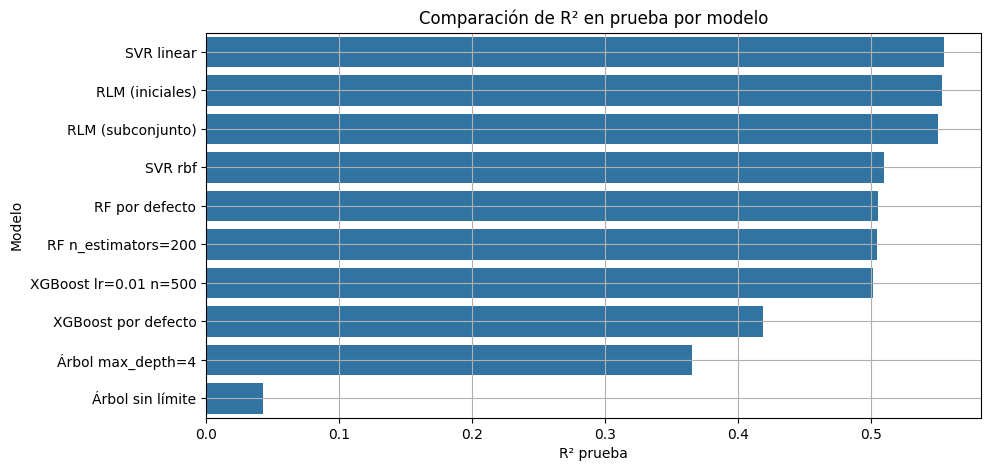

In [29]:
plt.figure(figsize=(10, 5))
sns.barplot(data=resultados, x='R² prueba', y='Modelo')
plt.title("Comparación de R² en prueba por modelo")
plt.grid(True)
plt.show()

In [30]:
## 10. Conclusiones

**1. Interpretación vs. Predicción**

Según los coeficientes estandarizados de la RLM, los 3 factores con mayor influencia son:
- **Índice Gini (+2.15):** a mayor desigualdad, mayor tasa de asesinatos. Es el factor más fuerte.
- **Tasa de desempleo juvenil (+1.64):** más desempleo juvenil se asocia con más asesinatos.
- **Porcentaje sin diploma de secundaria (+1.23):** menor nivel educativo, mayor tasa.

Le sigue de cerca **ingresos medios (−1.06)**, el principal factor con efecto negativo: a mayores ingresos, menor tasa. Todo esto bajo la condición *ceteris paribus*.

**2. Mejor Rendimiento**

El R² más alto en prueba fue el de **SVR con kernel linear (0.555)**, prácticamente empatado con la **RLM (0.553)**. Su superioridad se debe a que la relación entre las variables y la tasa de asesinatos es principalmente **lineal**: los modelos lineales capturan bien esa estructura, mientras que los modelos no lineales (árboles, RF, XGBoost) intentan buscar patrones más complejos que no existen y terminan ajustándose al ruido. Además, ningún modelo supera ~0.55, lo que indica que cerca del 45% de la variación depende de factores no incluidos en el dataset.

**3. Importancia de Variables**

- RLM (coeficientes estandarizados): Gini, desempleo juvenil, sin diploma.
- Random Forest y XGBoost: Gini, sin diploma, desempleo juvenil.

**Son las mismas tres variables**, solo cambia el orden entre desempleo y sin diploma. Esto refuerza que esas son las variables realmente relevantes. La diferencia es que los modelos no lineales reparten algo de importancia a variables como densidad o gasto policial, porque las usan para hacer divisiones (aunque aporten poco), y su importancia mide qué tanto se usa la variable para dividir, no la dirección del efecto.

**4. Sobreajuste (Overfitting)**

- Árbol con max_depth=4: R² entrenamiento 0.43 vs prueba 0.37 → diferencia pequeña, generaliza razonablemente.
- Árbol sin límite: R² entrenamiento **1.00** vs prueba **0.04** → el árbol memorizó perfectamente los datos de entrenamiento, pero falla casi por completo con datos nuevos.

Esa enorme diferencia entre entrenamiento y prueba es la evidencia clara del sobreajuste.

**5. Recomendación de Modelo**

Recomendaría la **Regresión Lineal Múltiple**. Su R² es de los más altos (0.55) y, sobre todo, es **interpretable**: cada coeficiente dice cuánto cambia la tasa de asesinatos por cada unidad de cambio en una variable. Eso permite presentar al gobierno un argumento claro y cuantificable, por ejemplo: "reducir la desigualdad o el desempleo juvenil se asocia con X asesinatos menos por cada 100 mil habitantes". Modelos como Random Forest o XGBoost son "cajas negras" que no indican la dirección ni la magnitud del efecto, por lo que no sirven para justificar una política pública.

Cabe señalar que en este dataset la inversión en programas sociales tiene un efecto negativo pero pequeño (−0.04 estandarizado). Para respaldar un programa social específico conviene enfocarlo en las variables con mayor peso, como el desempleo juvenil o la educación.

SyntaxError: invalid character '−' (U+2212) (4235047062.py, line 10)